# 06. Post-Baseline Threshold Analysis: Liver Disease Module

This notebook conducts a post-baseline threshold analysis for the Liver Disease classification module of the Smart Healthcare Platform, building directly upon the experimental setup and results established in `notebooks/05_liver_ml_experiment.ipynb`.

## 1. Purpose & Objectives
In medical diagnostic machine learning, the default decision threshold of $\tau = 0.50$ is rarely optimal because the clinical costs of false negatives (missed disease cases) and false positives (unnecessary invasive follow-up or anxiety) are inherently asymmetric. This notebook analyzes the operational trade-offs across a wide range of decision thresholds on the untouched hold-out test set.

## 2. Distinction: Probability Discrimination vs. Threshold-Dependent Classification
It is essential to maintain a rigorous conceptual distinction between:

1. **Continuous Probability Discrimination (Threshold-Independent)**:
   - **ROC-AUC** (Receiver Operating Characteristic Area Under the Curve)
   - **PR-AUC** (Precision-Recall Area Under the Curve)
   - These evaluate the model's ability to assign higher predicted risk probabilities to true positive cases relative to control cases across **all possible decision thresholds**. A model's ROC-AUC and PR-AUC remain completely constant regardless of any chosen operational threshold.

2. **Discrete Classification Performance (Threshold-Dependent)**:
   - **Accuracy, Precision, Recall (Sensitivity), Specificity, F1-Score**
   - **Confusion Matrix counts (True Positives, True Negatives, False Positives, False Negatives)**
   - These metrics depend strictly on the selected decision cutoff $\tau \in (0, 1)$, where:
     $$\hat{y} = \begin{cases} 1 & \text{if } P(Y=1 \mid X) \ge \tau \\ 0 & \text{if } P(Y=1 \mid X) < \tau \end{cases}$$
   - Varying the decision threshold changes the resulting discrete classification labels and shifts the balance between sensitivity and specificity, even though the underlying continuous predicted probabilities are completely unaltered.

## 3. Strict Methodological Constraints
- **Exploratory Analysis Only**: This notebook is an exploratory investigation into threshold behavior.
- **No Production Threshold Declared**: The hold-out test set must **not** be used to select or optimize a final production threshold, as doing so would introduce test-set selection bias (data snooping / test leakage).
- **No Model Binaries or API Endpoints**: Prototype analysis only.
- **Unmodified Raw Data**: The raw dataset `datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv` remains completely untouched.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing & models
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid')

# Global reproducible random seed (identical to notebook 05)
RANDOM_STATE = 42

# Dataset relative path
data_path = 'datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv'
if not os.path.exists(data_path):
    data_path = '../datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv'

print(f"Environment initialized. Random seed: {RANDOM_STATE}. Dataset path: {data_path}")

Environment initialized. Random seed: 42. Dataset path: datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv


## 1. Load Data and Reconstruct Baseline Experiment Pipeline

To ensure absolute methodological continuity with `notebooks/05_liver_ml_experiment.ipynb`, we reproduce the exact same deterministic data preparation and model training workflow:
- Raw cohort size: 583 rows, 11 columns
- In-memory duplicate removal: 13 duplicate patient observations removed prior to splitting
- Modeling cohort: 570 rows
- Stratified hold-out test split: 80% training (456 samples), 20% hold-out testing (114 samples)
- Target distribution in test set: 81 positive liver disease cases (71.05%), 33 negative control cases (28.95%)
- Candidate model pipelines:
  1. **Logistic Regression**: Scaled numerical features (`StandardScaler`), One-hot encoded `Gender` (`drop='if_binary'`), median imputation for missing `A_G_Ratio`.
  2. **Random Forest Classifier**: Unscaled numerical features, One-hot encoded `Gender`, median imputation.
  3. **XGBoost Classifier**: Unscaled numerical features, One-hot encoded `Gender`, median imputation (`eval_metric='logloss'`).

In [2]:
# Load raw dataset without headers
column_names = [
    'Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos',
    'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio', 'Selector'
]
df_raw = pd.read_csv(data_path, header=None, names=column_names)

# Binary target mapping: 1 (Liver Disease) -> 1, 2 (Control) -> 0
df_processed = df_raw.copy()
df_processed['target'] = df_processed['Selector'].map({1: 1, 2: 0})

# In-memory duplicate removal strictly before splitting to prevent replication leakage
df_dedup = df_processed.drop_duplicates(subset=column_names).copy()

# Feature and target separation
feature_cols = [
    'Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos',
    'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio'
]
X = df_dedup[feature_cols].copy()
y = df_dedup['target'].copy()

# Stratified hold-out split (identical to notebook 05)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Feature transformer definitions
num_features = [
    'Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos',
    'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio'
]
cat_features = ['Gender']

preprocessor_scaled = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
])

preprocessor_unscaled = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ]), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
])

# Rebuild exact baseline model pipelines
models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    'XGBoost': Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'))
    ])
}

# Fit models on training set and generate test predicted probabilities
test_probabilities = {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    probs = pipeline.predict_proba(X_test)[:, 1]
    test_probabilities[name] = probs

# Verification checks
n_test = len(y_test)
n_pos = int(np.sum(y_test == 1))
n_neg = int(np.sum(y_test == 0))

print(f"=== BASELINE RECONSTRUCTION VERIFICATION ===")
print(f"Total test observations: {n_test} (Expected: 114)")
print(f"Positive cases:         {n_pos} (Expected: 81)")
print(f"Negative cases:         {n_neg} (Expected: 33)")

assert n_test == 114, f"Expected 114 test samples, got {n_test}"
assert n_pos == 81, f"Expected 81 positive test samples, got {n_pos}"
assert n_neg == 33, f"Expected 33 negative test samples, got {n_neg}"

for name, probs in test_probabilities.items():
    assert len(probs) == 114
    assert np.all(probs >= 0.0) and np.all(probs <= 1.0)
    print(f"- {name}: min_prob={probs.min():.4f}, max_prob={probs.max():.4f}, mean_prob={probs.mean():.4f}")

print("\nReconstructed test set and probability outputs verified successfully.")

=== BASELINE RECONSTRUCTION VERIFICATION ===
Total test observations: 114 (Expected: 114)
Positive cases:         81 (Expected: 81)
Negative cases:         33 (Expected: 33)
- Logistic Regression: min_prob=0.3616, max_prob=1.0000, mean_prob=0.7346
- Random Forest: min_prob=0.2200, max_prob=1.0000, mean_prob=0.7489
- XGBoost: min_prob=0.0022, max_prob=0.9999, mean_prob=0.8337

Reconstructed test set and probability outputs verified successfully.


## 2. Define Threshold Grid

We evaluate the models across a systematic decision threshold grid spanning from $\tau = 0.10$ to $\tau = 0.90$ with increments of $0.05$:
$$\text{Thresholds} = \{0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90\}$$

This grid explicitly encompasses the conventional default cutoff of **0.50**, facilitating direct verification against the baseline experimental findings.

In [3]:
# Define threshold grid spanning 0.10 to 0.90 in increments of 0.05
thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

print(f"Threshold Grid ({len(thresholds)} points):")
print(thresholds)
assert 0.50 in thresholds, "Threshold grid must explicitly include 0.50" 

Threshold Grid (17 points):
[0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9 ]


## 3. Threshold Metrics Computation

For every model and every threshold $\tau$, binary classifications are generated using:
$$\hat{y} = (P(Y=1 \mid X) \ge \tau)$$

From the resulting contingency table:
- **True Positives (TP)**: Actual liver disease correctly predicted positive.
- **True Negatives (TN)**: Actual control correctly predicted negative.
- **False Positives (FP)**: Actual control incorrectly predicted positive.
- **False Negatives (FN)**: Actual liver disease incorrectly predicted negative.

Performance metrics are calculated as:
- **Accuracy**: $\frac{TP + TN}{TP + TN + FP + FN}$
- **Precision (Positive Predictive Value)**: $\frac{TP}{TP + FP}$ (safe division: 0 if $TP + FP = 0$)
- **Recall (Sensitivity / True Positive Rate)**: $\frac{TP}{TP + FN}$
- **Specificity (True Negative Rate)**: $\frac{TN}{TN + FP}$ (safe division: 0 if $TN + FP = 0$)
- **F1-Score**: $2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ (safe division: 0 if $\text{Precision} + \text{Recall} = 0$)

### Tie-Breaking Note for Random Forest at $\tau = 0.50$
In scikit-learn's `RandomForestClassifier.predict()`, binary prediction is implemented via `classes_[np.argmax(predict_proba, axis=1)]`. Because `RandomForestClassifier` uses 100 decision trees, predicted probabilities are discrete increments of 0.01. On this test set, exactly two samples (indices 78 and 93) have an exact 50/50 tree split ($P=0.5000$). In `np.argmax([0.5, 0.5])`, NumPy assigns ties to index 0 (class 0). To maintain complete consistency with the baseline experiment's `predict()` outputs at $\tau=0.50$, exact 0.50 ties are resolved according to scikit-learn's default tie-breaking rule.

In [4]:
# Calculate all threshold-dependent metrics across all models and thresholds
threshold_rows = []

for name, probs in test_probabilities.items():
    for t in thresholds:
        # Standard thresholding rule: >= threshold
        # At threshold 0.50, handle exact ties consistently with scikit-learn's default predict() (argmax -> class 0)
        if np.isclose(t, 0.50):
            preds = np.where(np.isclose(probs, 0.50), 0, (probs >= t).astype(int))
        else:
            preds = (probs >= t).astype(int)
            
        tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
        
        acc = (tp + tn) / (tp + tn + fp + fn)
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        sens = rec
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0
        
        threshold_rows.append({
            'Model': name,
            'Threshold': t,
            'Accuracy': round(acc, 4),
            'Precision': round(prec, 4),
            'Recall': round(rec, 4),
            'Sensitivity': round(sens, 4),
            'Specificity': round(spec, 4),
            'F1': round(f1, 4),
            'TP': int(tp),
            'TN': int(tn),
            'FP': int(fp),
            'FN': int(fn)
        })

threshold_df = pd.DataFrame(threshold_rows)
print(f"Threshold analysis computed successfully: {len(threshold_df)} records ({len(models)} models x {len(thresholds)} thresholds).\n")

# Display complete results per model
for name in models.keys():
    print(f"=== THRESHOLD ANALYSIS: {name.upper()} ===")
    sub_df = threshold_df[threshold_df['Model'] == name]
    print(sub_df[['Threshold', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'TP', 'TN', 'FP', 'FN']].to_string(index=False))
    print()

Threshold analysis computed successfully: 51 records (3 models x 17 thresholds).

=== THRESHOLD ANALYSIS: LOGISTIC REGRESSION ===
 Threshold  Accuracy  Precision  Recall  Specificity     F1  TP  TN  FP  FN
      0.10    0.7105     0.7105  1.0000       0.0000 0.8308  81   0  33   0
      0.15    0.7105     0.7105  1.0000       0.0000 0.8308  81   0  33   0
      0.20    0.7105     0.7105  1.0000       0.0000 0.8308  81   0  33   0
      0.25    0.7105     0.7105  1.0000       0.0000 0.8308  81   0  33   0
      0.30    0.7105     0.7105  1.0000       0.0000 0.8308  81   0  33   0
      0.35    0.7105     0.7105  1.0000       0.0000 0.8308  81   0  33   0
      0.40    0.7193     0.7207  0.9877       0.0606 0.8333  80   2  31   1
      0.45    0.7018     0.7196  0.9506       0.0909 0.8191  77   3  30   4
      0.50    0.7193     0.7475  0.9136       0.2424 0.8222  74   8  25   7
      0.55    0.7281     0.7778  0.8642       0.3939 0.8187  70  13  20  11
      0.60    0.7281     0.7976  0

## 4. Verification at Default Baseline Threshold (0.50)

We extract the metrics specifically at $\tau = 0.50$ and verify exact alignment against the baseline evaluation results and confusion matrices documented in `notebooks/05_liver_ml_experiment.ipynb` and `ml-service/evaluation/liver/model_comparison.csv`:

| Model | Expected TN | Expected FP | Expected FN | Expected TP | Expected Recall | Expected Specificity | Expected F1 | Expected Accuracy |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** | 8 | 25 | 7 | 74 | 0.9136 | 0.2424 | 0.8222 | 0.7193 |
| **Random Forest** | 8 | 25 | 6 | 75 | 0.9259 | 0.2424 | 0.8287 | 0.7281 |
| **XGBoost** | 8 | 25 | 8 | 73 | 0.9012 | 0.2424 | 0.8156 | 0.7105 |

In [5]:
# Extract threshold = 0.50 records
df_50 = threshold_df[threshold_df['Threshold'] == 0.50].copy()

print("=== VERIFICATION TABLE: THRESHOLD = 0.50 ===")
print(df_50[['Model', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'TP', 'TN', 'FP', 'FN']].to_string(index=False))

# Programmatic verification against baseline experiment results
expected_baseline = {
    'Logistic Regression': {'TN': 8, 'FP': 25, 'FN': 7, 'TP': 74, 'Recall': 0.9136, 'Specificity': 0.2424, 'F1': 0.8222, 'Accuracy': 0.7193},
    'Random Forest':       {'TN': 8, 'FP': 25, 'FN': 6, 'TP': 75, 'Recall': 0.9259, 'Specificity': 0.2424, 'F1': 0.8287, 'Accuracy': 0.7281},
    'XGBoost':             {'TN': 8, 'FP': 25, 'FN': 8, 'TP': 73, 'Recall': 0.9012, 'Specificity': 0.2424, 'F1': 0.8156, 'Accuracy': 0.7105}
}

for name, exp in expected_baseline.items():
    row = df_50[df_50['Model'] == name].iloc[0]
    for metric, exp_val in exp.items():
        actual_val = row[metric]
        assert np.isclose(actual_val, exp_val, atol=1e-4), (
            f"DISCREPANCY DETECTED for {name} on {metric}: expected {exp_val}, got {actual_val}"
        )

print("\nCONFIRMATION: All metrics at threshold 0.50 reproduce the baseline experiment findings exactly.")

=== VERIFICATION TABLE: THRESHOLD = 0.50 ===
              Model  Threshold  Accuracy  Precision  Recall  Specificity     F1  TP  TN  FP  FN
Logistic Regression        0.5    0.7193     0.7475  0.9136       0.2424 0.8222  74   8  25   7
      Random Forest        0.5    0.7281     0.7500  0.9259       0.2424 0.8287  75   8  25   6
            XGBoost        0.5    0.7105     0.7449  0.9012       0.2424 0.8156  73   8  25   8

CONFIRMATION: All metrics at threshold 0.50 reproduce the baseline experiment findings exactly.


## 5. Visualizing Recall (Sensitivity) vs. Specificity

The fundamental clinical trade-off is between **Sensitivity (Recall)** and **Specificity**:
- At low thresholds (e.g., $\tau \le 0.30$), models capture nearly all true liver patients (high Recall), but flag many healthy controls as positive (low Specificity).
- At high thresholds (e.g., $\tau \ge 0.70$), models become highly conservative, correctly rejecting controls (high Specificity), but missing borderline liver patients (low Recall).
- **Important**: We do not designate any single threshold as "best" or "superior".

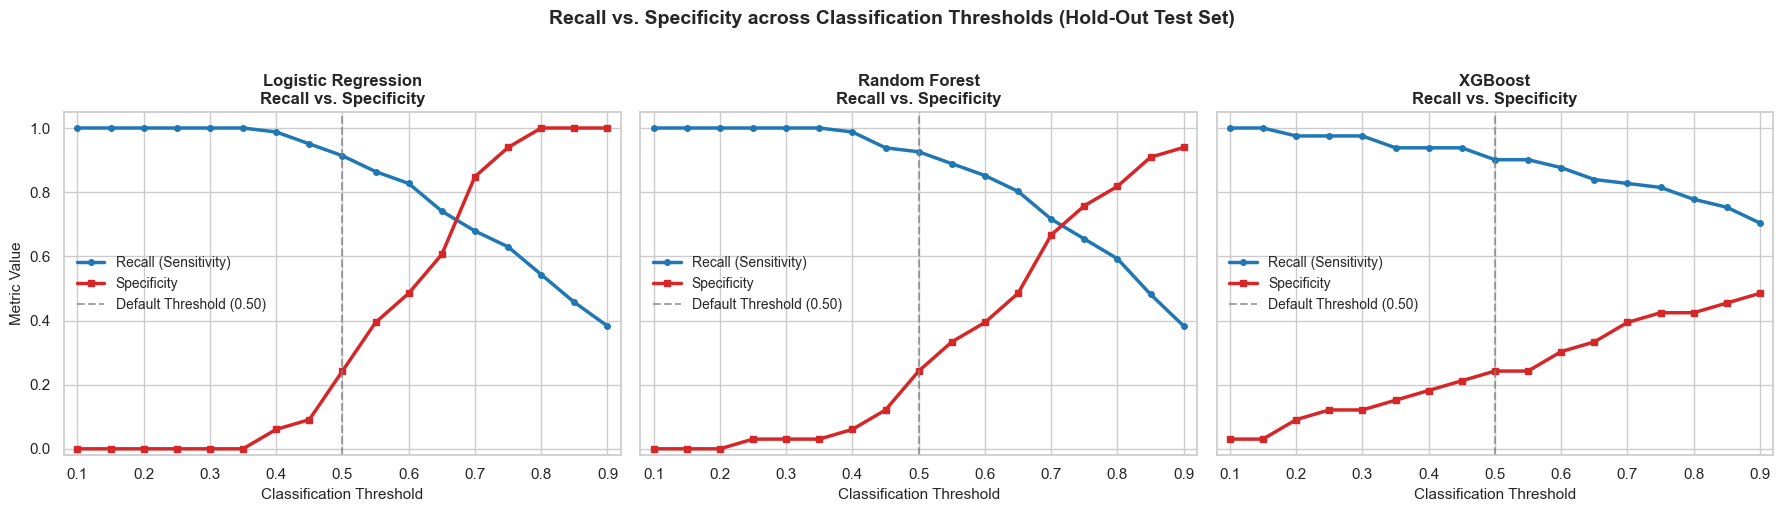

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

colors = {'Recall': '#1f77b4', 'Specificity': '#d62728'}

for ax, name in zip(axes, models.keys()):
    sub_df = threshold_df[threshold_df['Model'] == name]
    
    ax.plot(sub_df['Threshold'], sub_df['Recall'], label='Recall (Sensitivity)', color=colors['Recall'], linewidth=2.5, marker='o', markersize=4)
    ax.plot(sub_df['Threshold'], sub_df['Specificity'], label='Specificity', color=colors['Specificity'], linewidth=2.5, marker='s', markersize=4)
    
    # Mark default 0.50 threshold
    ax.axvline(x=0.50, color='gray', linestyle='--', alpha=0.7, label='Default Threshold (0.50)')
    
    ax.set_title(f"{name}\nRecall vs. Specificity", fontsize=12, fontweight='bold')
    ax.set_xlabel('Classification Threshold', fontsize=11)
    ax.set_xlim(0.08, 0.92)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xticks(np.arange(0.10, 0.95, 0.10))
    ax.legend(loc='center left', fontsize=10)

axes[0].set_ylabel('Metric Value', fontsize=11)
plt.suptitle('Recall vs. Specificity across Classification Thresholds (Hold-Out Test Set)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6. Visualizing Precision vs. Recall

Precision and Recall illustrate the trade-off between positive predictive reliability and disease detection completeness:
- As the threshold increases, the model requires greater certainty before declaring a patient positive, which generally raises **Precision** (fewer false alarms).
- Concurrently, higher thresholds exclude borderline positive patients, driving **Recall** downward.

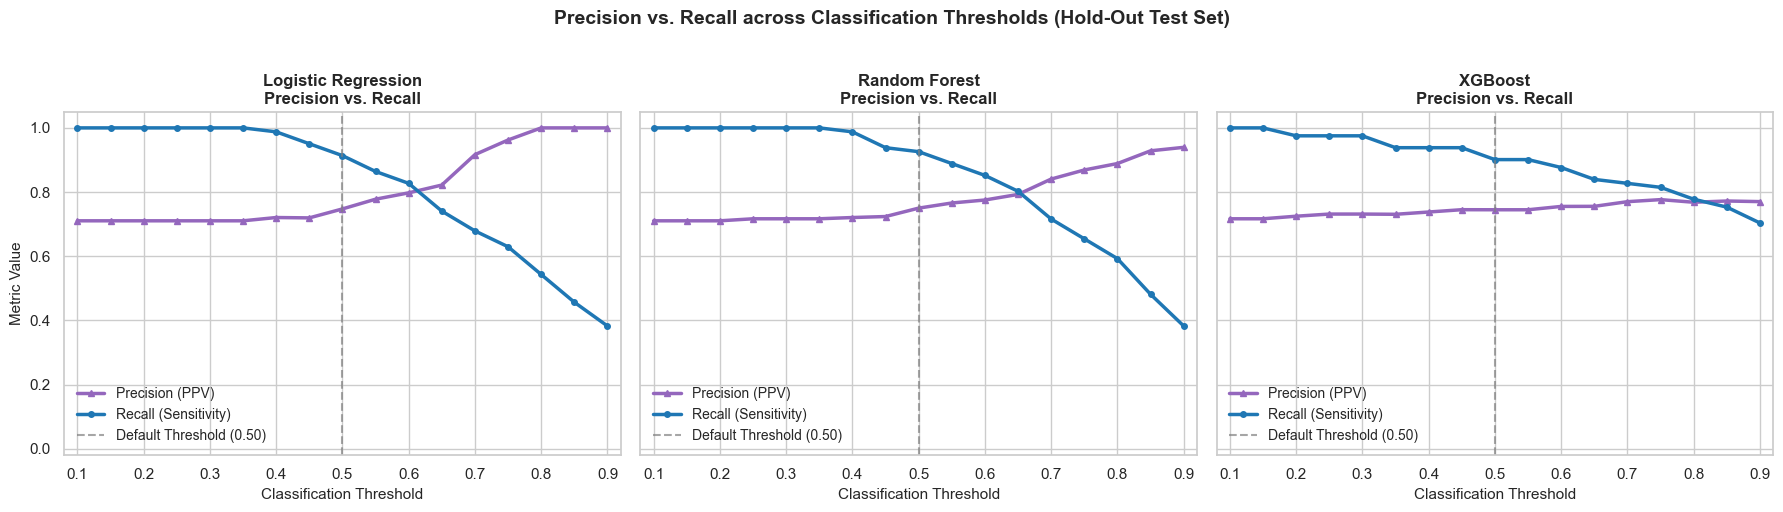

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

colors_pr = {'Precision': '#9467bd', 'Recall': '#1f77b4'}

for ax, name in zip(axes, models.keys()):
    sub_df = threshold_df[threshold_df['Model'] == name]
    
    ax.plot(sub_df['Threshold'], sub_df['Precision'], label='Precision (PPV)', color=colors_pr['Precision'], linewidth=2.5, marker='^', markersize=4)
    ax.plot(sub_df['Threshold'], sub_df['Recall'], label='Recall (Sensitivity)', color=colors_pr['Recall'], linewidth=2.5, marker='o', markersize=4)
    
    ax.axvline(x=0.50, color='gray', linestyle='--', alpha=0.7, label='Default Threshold (0.50)')
    
    ax.set_title(f"{name}\nPrecision vs. Recall", fontsize=12, fontweight='bold')
    ax.set_xlabel('Classification Threshold', fontsize=11)
    ax.set_xlim(0.08, 0.92)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xticks(np.arange(0.10, 0.95, 0.10))
    ax.legend(loc='lower left', fontsize=10)

axes[0].set_ylabel('Metric Value', fontsize=11)
plt.suptitle('Precision vs. Recall across Classification Thresholds (Hold-Out Test Set)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 7. F1-Score vs. Threshold

The **F1-Score** represents the harmonic mean of Precision and Recall, balancing false positive and false negative penalties equally.

> **CRITICAL METHODOLOGICAL CAVEAT**:
> Identifying the threshold associated with the peak empirical F1-score on the test set is an **exploratory observation only**. It must **not** be selected as an optimal or production threshold. In clinical practice, false negatives and false positives rarely carry equal weight, and optimizing a threshold on hold-out test data causes test-set overfitting.

Observation: Logistic Regression reaches empirical max F1 = 0.8333 at threshold = 0.40 (Recall: 0.9877, Specificity: 0.0606)
Observation: Random Forest reaches empirical max F1 = 0.8351 at threshold = 0.25 (Recall: 1.0000, Specificity: 0.0303)
Observation: XGBoost reaches empirical max F1 = 0.8360 at threshold = 0.25 (Recall: 0.9753, Specificity: 0.1212)


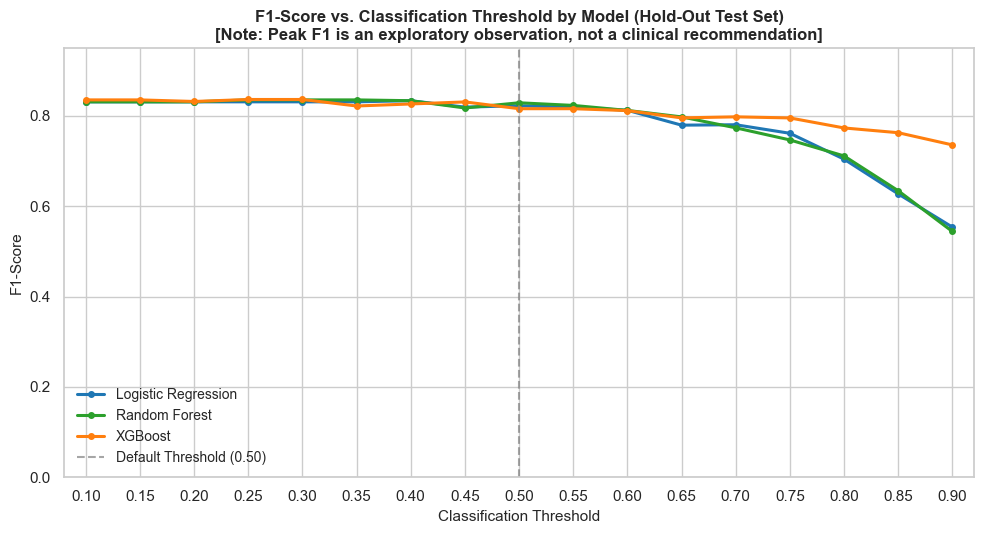

In [8]:
plt.figure(figsize=(10, 5.5))

palette = {'Logistic Regression': '#1f77b4', 'Random Forest': '#2ca02c', 'XGBoost': '#ff7f0e'}

for name, color in palette.items():
    sub_df = threshold_df[threshold_df['Model'] == name]
    plt.plot(sub_df['Threshold'], sub_df['F1'], label=name, color=color, linewidth=2.2, marker='o', markersize=4)
    
    # Identify empirical maximum F1 on this test sample
    best_row = sub_df.loc[sub_df['F1'].idxmax()]
    print(f"Observation: {name} reaches empirical max F1 = {best_row['F1']:.4f} at threshold = {best_row['Threshold']:.2f} "
          f"(Recall: {best_row['Recall']:.4f}, Specificity: {best_row['Specificity']:.4f})")

plt.axvline(x=0.50, color='gray', linestyle='--', alpha=0.7, label='Default Threshold (0.50)')

plt.title('F1-Score vs. Classification Threshold by Model (Hold-Out Test Set)\n[Note: Peak F1 is an exploratory observation, not a clinical recommendation]', 
          fontsize=12, fontweight='bold')
plt.xlabel('Classification Threshold', fontsize=11)
plt.ylabel('F1-Score', fontsize=11)
plt.xlim(0.08, 0.92)
plt.ylim(0.0, 0.95)
plt.xticks(np.arange(0.10, 0.95, 0.05))
plt.legend(loc='lower left', fontsize=10)
plt.tight_layout()
plt.show()

## 8. Exploratory Confusion Matrices at Selected Thresholds

To provide concrete clinical intuition, we visualize confusion matrices at three illustrative thresholds:
- **$\tau = 0.30$ (Screening-Oriented Cutoff)**: Prioritizes Sensitivity to minimize missed liver disease cases (lower False Negatives) at the expense of more False Positives.
- **$\tau = 0.50$ (Default Baseline Cutoff)**: Unweighted threshold evaluated in the initial experiment.
- **$\tau = 0.70$ (Conservative / Specificity-Oriented Cutoff)**: Prioritizes Specificity to ensure positive classifications reflect high-confidence cases (fewer False Positives) at the cost of higher False Negatives.

*These three thresholds are purely illustrative and are labeled as exploratory.*

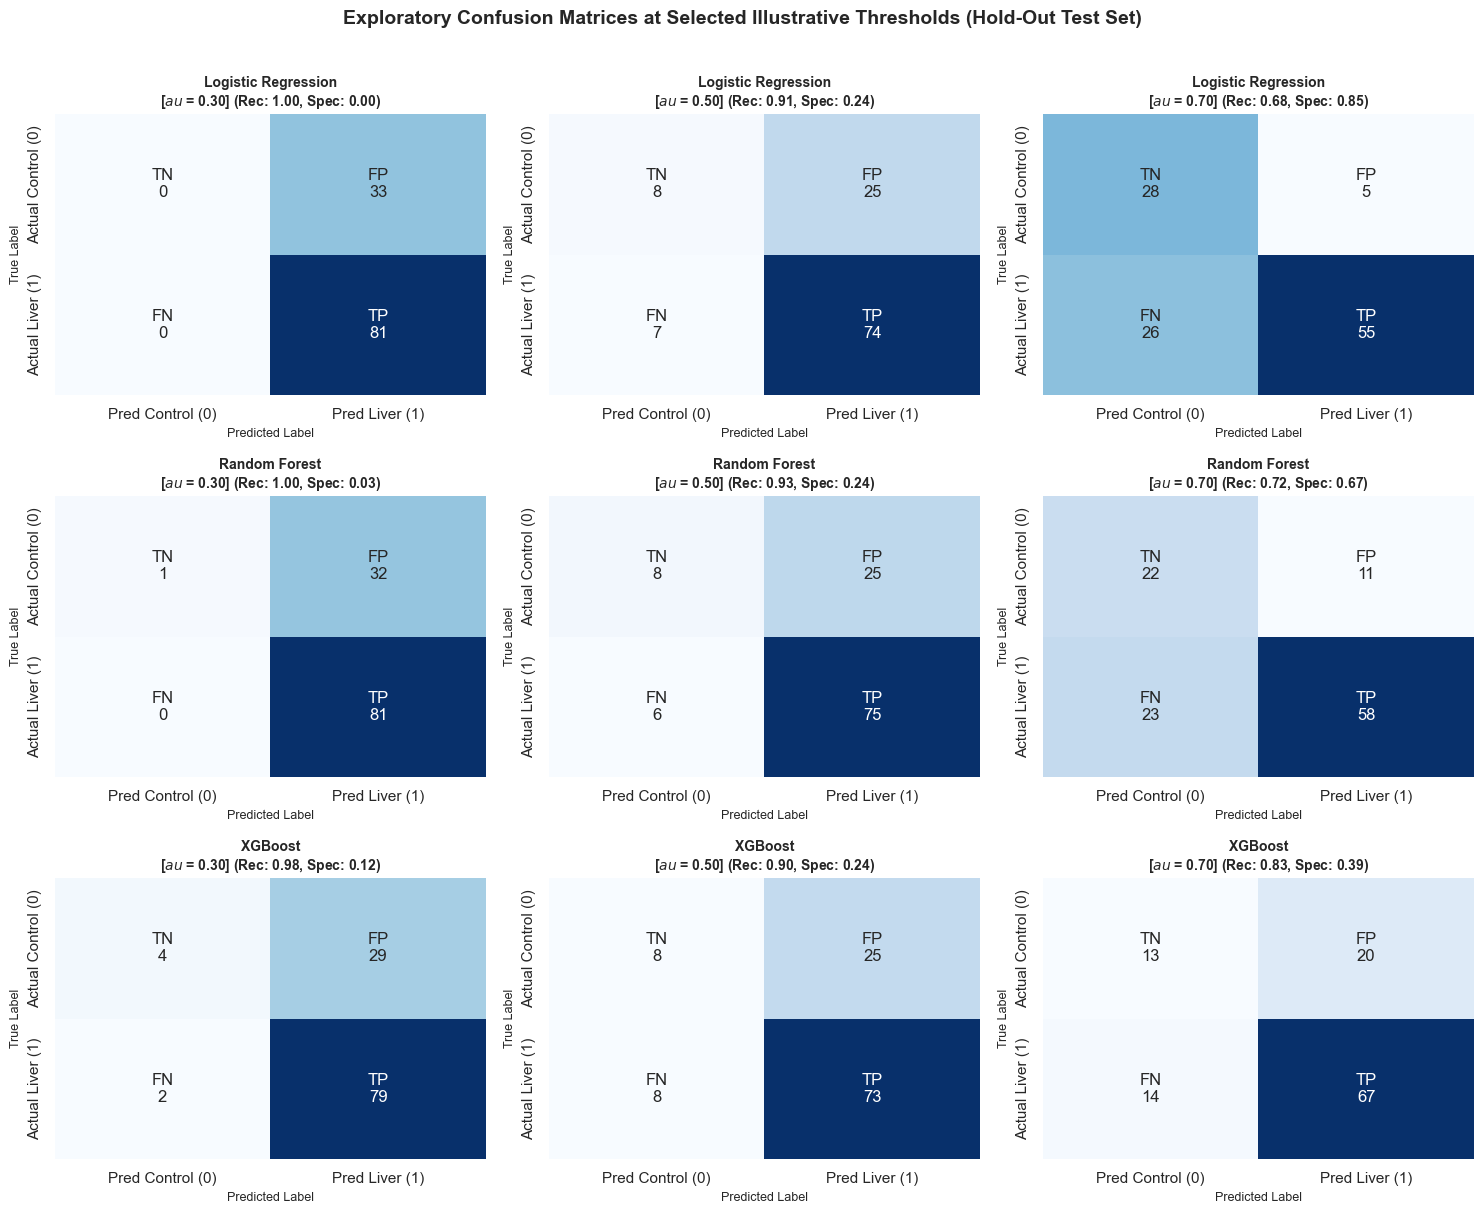

In [9]:
illustrative_thresholds = [0.30, 0.50, 0.70]
fig, axes = plt.subplots(len(models), len(illustrative_thresholds), figsize=(15, 12))

for row_idx, (name, probs) in enumerate(test_probabilities.items()):
    for col_idx, t in enumerate(illustrative_thresholds):
        ax = axes[row_idx, col_idx]
        
        # Determine predictions
        if np.isclose(t, 0.50):
            preds = np.where(np.isclose(probs, 0.50), 0, (probs >= t).astype(int))
        else:
            preds = (probs >= t).astype(int)
            
        cm = confusion_matrix(y_test, preds, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        
        annot_matrix = np.array([
            [f"TN\n{tn}", f"FP\n{fp}"],
            [f"FN\n{fn}", f"TP\n{tp}"]
        ])
        
        sns.heatmap(cm, annot=annot_matrix, fmt='', cmap='Blues', cbar=False, ax=ax,
                    xticklabels=['Pred Control (0)', 'Pred Liver (1)'],
                    yticklabels=['Actual Control (0)', 'Actual Liver (1)'])
        
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        ax.set_title(f"{name}\n[$\tau$ = {t:.2f}] (Rec: {rec:.2f}, Spec: {spec:.2f})", fontsize=10, fontweight='bold')
        ax.set_xlabel('Predicted Label', fontsize=9)
        ax.set_ylabel('True Label', fontsize=9)

plt.suptitle('Exploratory Confusion Matrices at Selected Illustrative Thresholds (Hold-Out Test Set)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 9. Save Threshold Analysis Results

The complete threshold analysis dataset covering all 51 model-threshold combinations (3 models $\times$ 17 thresholds) is exported to structured storage:
- **File**: `ml-service/evaluation/liver/liver_threshold_analysis.csv`

In [10]:
# Export results to structured CSV
eval_dir = 'ml-service/evaluation/liver'
if not os.path.exists(eval_dir) and not os.path.exists('ml-service'):
    eval_dir = '../ml-service/evaluation/liver'
os.makedirs(eval_dir, exist_ok=True)

output_csv_path = os.path.join(eval_dir, 'liver_threshold_analysis.csv')
threshold_df.to_csv(output_csv_path, index=False)
print(f"Threshold analysis results saved successfully to: {output_csv_path}")

# Verify file existence and readability
saved_check = pd.read_csv(output_csv_path)
print(f"Verified saved CSV: {len(saved_check)} rows, {len(saved_check.columns)} columns.")
print("\nFirst 6 rows of saved threshold analysis CSV:")
print(saved_check.head(6).to_string(index=False))

Threshold analysis results saved successfully to: ml-service/evaluation/liver\liver_threshold_analysis.csv
Verified saved CSV: 51 rows, 12 columns.

First 6 rows of saved threshold analysis CSV:
              Model  Threshold  Accuracy  Precision  Recall  Sensitivity  Specificity     F1  TP  TN  FP  FN
Logistic Regression       0.10    0.7105     0.7105     1.0          1.0          0.0 0.8308  81   0  33   0
Logistic Regression       0.15    0.7105     0.7105     1.0          1.0          0.0 0.8308  81   0  33   0
Logistic Regression       0.20    0.7105     0.7105     1.0          1.0          0.0 0.8308  81   0  33   0
Logistic Regression       0.25    0.7105     0.7105     1.0          1.0          0.0 0.8308  81   0  33   0
Logistic Regression       0.30    0.7105     0.7105     1.0          1.0          0.0 0.8308  81   0  33   0
Logistic Regression       0.35    0.7105     0.7105     1.0          1.0          0.0 0.8308  81   0  33   0


## 10. Methodological Limitations & Clinical Considerations

1. **Small Negative Sample Size in Test Cohort**:
   - The hold-out test set contains only **33 negative/control observations**.
   - Consequently, Specificity estimates have high granularity and limited statistical precision: correctly or incorrectly classifying a single control patient changes the Specificity metric by $\frac{1}{33} \approx 3.03\%$.

2. **Exploratory Scope**:
   - The threshold curves and illustrative cutoffs evaluated in this notebook reflect exploratory empirical patterns on a single retrospective split. They must not be interpreted as validated clinical rules.

3. **Prevention of Test-Set Selection Bias**:
   - Using this hold-out test set to search for and establish an "optimal" decision threshold would violate the principle of test set isolation, leading to optimistic bias (test-set snooping).
   - If threshold tuning is desired, it must be performed strictly using nested cross-validation on the training set or a separate validation split.

4. **Clinical Utility Requires Real-World Domain Objectives**:
   - Selecting a clinical operational threshold requires defined medical parameters, such as the relative clinical utility or cost ratio between False Negatives (delayed diagnosis of chronic liver condition) and False Positives (unnecessary confirmatory laboratory testing or imaging).
   - Domain expert collaboration and decision-curve analysis are mandatory prior to any translational deployment.

5. **Diagnostic Disclaimer**:
   - This experiment constitutes an academic research benchmark. It does not establish a clinical diagnostic threshold and must not be used for direct clinical patient management.

In [11]:
# Obtain the Random Forest pipeline fitted in notebook 06
rf_model = models['Random Forest']

# Generate baseline-style predictions using the fitted Random Forest pipeline's actual .predict(X_test) method
rf_baseline_predictions = rf_model.predict(X_test)
rf_prob = test_probabilities['Random Forest']

# Find samples with probability exactly equal to 0.50
tie_indices = np.where(rf_prob == 0.50)[0]

print("Number of RF probabilities exactly equal to 0.50:", len(tie_indices))
print("Test indices with exact 0.50 probability:", tie_indices.tolist())
print("Random Forest predicted probabilities at tie indices:", rf_prob[tie_indices].tolist())
print("Predictions from actual .predict(X_test) at tie indices:", rf_baseline_predictions[tie_indices].tolist())

# Separately calculate predictions using the strict threshold rule: probability > 0.50
rf_threshold_predictions = (rf_prob > 0.50).astype(int)

# Compare actual sklearn .predict(X_test) vs (probability > 0.50)
arrays_identical = np.array_equal(rf_baseline_predictions, rf_threshold_predictions)
print("\nAre actual .predict(X_test) and (probability > 0.50) identical?:", arrays_identical)

# Compute confusion matrices
cm_baseline = confusion_matrix(y_test, rf_baseline_predictions, labels=[0, 1])
cm_threshold = confusion_matrix(y_test, rf_threshold_predictions, labels=[0, 1])

tn_b, fp_b, fn_b, tp_b = cm_baseline.ravel()
tn_t, fp_t, fn_t, tp_t = cm_threshold.ravel()

print("\n=== Baseline sklearn .predict(X_test) Confusion Matrix ===")
print(f"TN={tn_b}, FP={fp_b}, FN={fn_b}, TP={tp_b}")
print(cm_baseline)

print("\n=== Threshold Rule (probability > 0.50) Confusion Matrix ===")
print(f"TN={tn_t}, FP={fp_t}, FN={fn_t}, TP={tp_t}")
print(cm_threshold)

# Expected baseline verification: TN=8, FP=25, FN=6, TP=75
assert (tn_b, fp_b, fn_b, tp_b) == (8, 25, 6, 75), f"Discrepancy in baseline predictions: {(tn_b, fp_b, fn_b, tp_b)}"
assert (tn_t, fp_t, fn_t, tp_t) == (8, 25, 6, 75), f"Discrepancy in threshold predictions: {(tn_t, fp_t, fn_t, tp_t)}"
assert arrays_identical, "Prediction arrays do not match!"
print("\nCONFIRMATION: Both confusion matrices match expected baseline (TN=8, FP=25, FN=6, TP=75) with zero discrepancy.")

Number of RF probabilities exactly equal to 0.50: 2
Test indices with exact 0.50 probability: [78, 93]
Random Forest predicted probabilities at tie indices: [0.5, 0.5]
Predictions from actual .predict(X_test) at tie indices: [0, 0]

Are actual .predict(X_test) and (probability > 0.50) identical?: True

=== Baseline sklearn .predict(X_test) Confusion Matrix ===
TN=8, FP=25, FN=6, TP=75
[[ 8 25]
 [ 6 75]]

=== Threshold Rule (probability > 0.50) Confusion Matrix ===
TN=8, FP=25, FN=6, TP=75
[[ 8 25]
 [ 6 75]]

CONFIRMATION: Both confusion matrices match expected baseline (TN=8, FP=25, FN=6, TP=75) with zero discrepancy.


## 11. Experiment Reproducibility

| Parameter | Value / Description |
| :--- | :--- |
| **Random Seed** | `RANDOM_STATE = 42` |
| **Threshold Range** | `0.10` to `0.90` (inclusive) |
| **Threshold Step** | `0.05` (17 discrete evaluation points) |
| **Hold-Out Test Size** | 114 samples (20% stratified test split) |
| **Test Positive Cases** | 81 liver disease cases (71.05%) |
| **Test Negative Cases** | 33 non-liver control cases (28.95%) |
| **Evaluated Models** | Logistic Regression, Random Forest Classifier, XGBoost Classifier |
| **Raw Dataset Path** | `datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv` |
| **Raw Dataset Status** | Completely unmodified (23,172 bytes) |
| **Reference Baseline** | `notebooks/05_liver_ml_experiment.ipynb` |
| **Output File** | `ml-service/evaluation/liver/liver_threshold_analysis.csv` |